In [1]:
from getpass import getpass
token = getpass("GitHub token: ")
!git clone https://{token}@github.com/AryanKpr/AIC-Research.git
%cd AIC-Research

GitHub token: ··········
Cloning into 'AIC-Research'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 36 (delta 9), reused 33 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 59.35 KiB | 8.48 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/AIC-Research


In [2]:
%cd /content/AIC-Research/
!git pull
!ls src
!nvidia-smi

/content/AIC-Research
Already up to date.
analyze.py  campaign.py  common.py  step4.py  test_flip.py  train.py
Mon Nov  9 03:14:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                            

In [3]:
!git config user.name "Aryan Kapoor"
!git config user.email "reply2aryankapoor@gmail.com"

In [4]:
!pip freeze | grep -E "^(torch|torchvision|numpy|pandas|matplotlib)==" > requirements.txt
!cat requirements.txt

matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
torch==2.14.1+cu130
torchvision==0.29.1+cu130


In [5]:
!python src/train.py

100% 9.91M/9.91M [00:01<00:00, 5.82MB/s]
100% 28.9k/28.9k [00:00<00:00, 134kB/s]
100% 1.65M/1.65M [00:01<00:00, 1.10MB/s]
100% 4.54k/4.54k [00:00<00:00, 18.6MB/s]
Parameters: 101770 (biases: 138)
epoch 1/5  last batch loss 0.1315
epoch 2/5  last batch loss 0.0527
epoch 3/5  last batch loss 0.0549
epoch 4/5  last batch loss 0.0554
epoch 5/5  last batch loss 0.0544
Saved /content/AIC-Research/models/mlp_fp32.pt
FP32 test accuracy: 0.9753
torch.float16 test accuracy: 0.9753  (difference +0.0000)


In [6]:
from google.colab import drive
drive.mount("/content/drive")
!cp models/mlp_fp32.pt /content/drive/MyDrive/

Mounted at /content/drive
^C


In [7]:
!python src/test_flip.py

0.5 bit 14 ->                  32768.0  expected 32768.0  OK
1.0 bit 14 ->                      inf  expected inf  OK
0.5 bit  0 ->            0.50048828125  expected 0.50048828125  OK
0.5 bit 15 ->                     -0.5  expected -0.5  OK
weight[0] after flip: -832.0
Outputs changed after flip: True
Restore verified: fingerprint and predictions match. All tests passed.


In [8]:
!cat logs/train_meta.json
!ls -la /content/drive/MyDrive/mlp_fp32.pt
!cat requirements.txt

{
  "train_seed": 1191607972,
  "epochs": 5,
  "batch": 128,
  "lr": 0.001,
  "acc_fp32": 0.9752999544143677,
  "acc_study_precision": 0.9752999544143677,
  "commit": "663d567cebd2f1ff98ae5cc794344588bcd30810",
  "uncommitted_changes": false,
  "master_seed": 20261104,
  "device": "Tesla T4",
  "dtype": "torch.float16",
  "torch": "2.14.1+cu130",
  "numpy": "2.4.6"
}-rw------- 1 root root 0 Nov  9 03:16 /content/drive/MyDrive/mlp_fp32.pt
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
torch==2.14.1+cu130
torchvision==0.29.1+cu130


In [9]:
!git add requirements.txt logs
!git commit -m "Pin versions, training results"
!git push

[main 77242de] Pin versions, training results
 2 files changed, 5 insertions(+), 5 deletions(-)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 560 bytes | 560.00 KiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/AryanKpr/AIC-Research.git
   663d567..77242de  main -> main


In [10]:
!git pull --no-rebase

Already up to date.


In [11]:
!git config core.editor true

In [12]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [13]:
!git commit --no-edit
!git push

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date


In [14]:
!git status
!git log --oneline -3
!grep "uncommitted_changes" src/common.py

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
77242de (HEAD -> main, origin/main, origin/HEAD) Pin versions, training results
663d567 Campaign run1 and run2, identical hashes
1e2133a Step 4: one weight through 16 bits
        "uncommitted_changes": git("status", "--porcelain", "--", "src") != "",


In [15]:
!pwd
!ls models

/content/AIC-Research
mlp_fp32.pt


In [16]:
!rm -rf AIC-Research
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [17]:
!python src/step4.py

Chosen element 33719, value -0.002044677734375, golden accuracy 0.9753

bit 15 sign      new value      0.002044677734375  masked     0.9753
bit 14 exponent  new value                 -134.0  SDC        0.5237
bit 13 exponent  new value             -0.5234375  SDC        0.9753
bit 12 exponent  new value -0.0001277923583984375  masked     0.9753
bit 11 exponent  new value   -0.00051116943359375  masked     0.9753
bit 10 exponent  new value      -0.00408935546875  masked     0.9753
bit  9 mantissa  new value     -0.003021240234375  masked     0.9753
bit  8 mantissa  new value     -0.002532958984375  masked     0.9753
bit  7 mantissa  new value     -0.002288818359375  masked     0.9753
bit  6 mantissa  new value     -0.002166748046875  masked     0.9753
bit  5 mantissa  new value     -0.001983642578125  masked     0.9753
bit  4 mantissa  new value      -0.00201416015625  masked     0.9753
bit  3 mantissa  new value    -0.0020599365234375  masked     0.9753
bit  2 mantissa  new value   -0

In [18]:
!git add logs
!git commit -m "Step 4: one weight through 16 bits"
!git push

[main 7f44b71] Step 4: one weight through 16 bits
 1 file changed, 2 insertions(+), 2 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 418 bytes | 418.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/AryanKpr/AIC-Research.git
   77242de..7f44b71  main -> main


In [19]:
!python src/campaign.py run1

Golden accuracy: 0.9753
320/4800 faults
640/4800 faults
960/4800 faults
1280/4800 faults
1600/4800 faults
1920/4800 faults
2240/4800 faults
2560/4800 faults
2880/4800 faults
3200/4800 faults
3520/4800 faults
3840/4800 faults
4160/4800 faults
4480/4800 faults
4800/4800 faults
Done: 4800 faults written to /content/AIC-Research/logs/campaign_run1.csv


In [20]:
!python src/campaign.py run2

Golden accuracy: 0.9753
320/4800 faults
640/4800 faults
960/4800 faults
1280/4800 faults
1600/4800 faults
1920/4800 faults
2240/4800 faults
2560/4800 faults
2880/4800 faults
3200/4800 faults
3520/4800 faults
3840/4800 faults
4160/4800 faults
4480/4800 faults
4800/4800 faults
Done: 4800 faults written to /content/AIC-Research/logs/campaign_run2.csv


In [21]:
!sha256sum logs/campaign_run1.csv logs/campaign_run2.csv

95778790bbc63742d9f03178c9787f80e88dfadbf5e508a702ad212089f27d21  logs/campaign_run1.csv
95778790bbc63742d9f03178c9787f80e88dfadbf5e508a702ad212089f27d21  logs/campaign_run2.csv


In [22]:
!git add logs configs
!git commit -m "Campaign run1 and run2, identical hashes"
!git push

[main 5279d09] Campaign run1 and run2, identical hashes
 2 files changed, 4 insertions(+), 4 deletions(-)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 487 bytes | 487.00 KiB/s, done.
Total 5 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 3 local objects.
To https://github.com/AryanKpr/AIC-Research.git
   7f44b71..5279d09  main -> main


In [23]:
!python src/analyze.py run1

 bit    field   n  masked_k  SDC_k  non-finite_k
  15     sign 300       151    149             0
  14 exponent 300        10    213            77
  13 exponent 300       165    135             0
  12 exponent 300        82    218             0
  11 exponent 300       169    131             0
  10 exponent 300       186    114             0
   9 mantissa 300       219     81             0
   8 mantissa 300       254     46             0
   7 mantissa 300       274     26             0
   6 mantissa 300       289     11             0
   5 mantissa 300       290     10             0
   4 mantissa 300       296      4             0
   3 mantissa 300       298      2             0
   2 mantissa 300       300      0             0
   1 mantissa 300       300      0             0
   0 mantissa 300       300      0             0
Saved /content/AIC-Research/figures/per_bit_run1.png
Saved /content/AIC-Research/figures/per_bit_run1_W1.png
Saved /content/AIC-Research/figures/per_bit_run1_W2.png


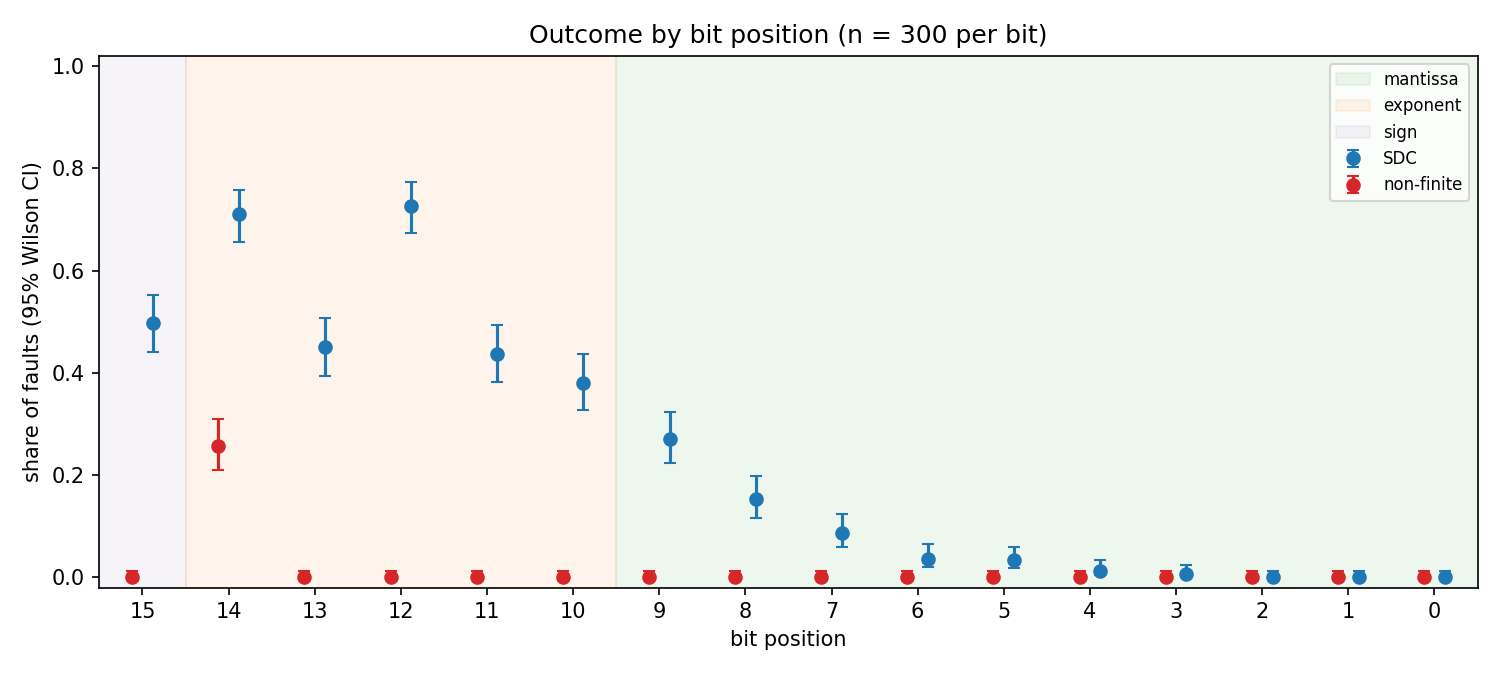

In [24]:
from IPython.display import Image
Image("figures/per_bit_run1.png")

In the graph, each bit position is on the x-axis, ordered from bit 15 (sign) on the left to bit 0 (lowest mantissa bit) on the right, matching how FP16 stores a number. The shaded backgrounds mark the three fields: sign (bit 15), exponent (bits 14–10), and mantissa (bits 9–0). The y-axis is the share of the 300 faults at that bit that ended in each outcome. Blue points are SDC, red points are non-finite, and each point has its 95% Wilson interval as error bars. Masked isn’t plotted, since it’s whatever remains: 1 − SDC − non-finite. The blue and red points are shifted slightly left and right at each bit so they don’t overlap.

In [25]:
!grep -E '"commit"|uncommitted|device' logs/campaign_run1_meta.json logs/campaign_run2_meta.json
!git status

logs/campaign_run1_meta.json:  "commit": "7f44b71fe95e513da97a68f9e002175ce532a855",
logs/campaign_run1_meta.json:  "uncommitted_changes": false,
logs/campaign_run1_meta.json:  "device": "Tesla T4",
logs/campaign_run2_meta.json:  "commit": "7f44b71fe95e513da97a68f9e002175ce532a855",
logs/campaign_run2_meta.json:  "uncommitted_changes": false,
logs/campaign_run2_meta.json:  "device": "Tesla T4",
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	logs/summary_run1.csv
	logs/summary_run1_W1.csv
	logs/summary_run1_W2.csv

nothing added to commit but untracked files present (use "git add" to track)
